In [1]:
!pip install -q torch torchvision matplotlib numpy pillow

In [2]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms
from google.colab import files

In [3]:
weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

model.eval()

print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 57.1MB/s]


Model loaded successfully!


Saving WhatsApp Image 2026-11-23 at 9.54.34 PM.jpeg to WhatsApp Image 2026-11-23 at 9.54.34 PM.jpeg


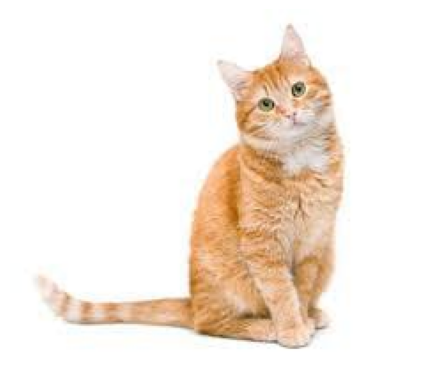

In [5]:
uploaded = files.upload()

filename = next(iter(uploaded))

image = Image.open(filename).convert("RGB")

plt.imshow(image)
plt.axis("off")
plt.show()

In [6]:
preprocess = weights.transforms()

input_tensor = preprocess(image)

input_tensor = input_tensor.unsqueeze(0)

print("Input shape:", input_tensor.shape)

Input shape: torch.Size([1, 3, 224, 224])


In [7]:
with torch.no_grad():
    output = model(input_tensor)

probabilities = torch.softmax(output, dim=1)

class_index = probabilities.argmax(dim=1).item()

labels = weights.meta["categories"]

predicted_label = labels[class_index]

confidence = probabilities[0, class_index].item() * 100

print("Predicted class:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

Predicted class: tabby
Confidence: 28.13 %


In [8]:
target_layer = model.layer4[-1]

activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

    output.register_hook(
        lambda grad: gradients.append(grad)
    )

handle = target_layer.register_forward_hook(forward_hook)

model.zero_grad()

output = model(input_tensor)

class_index = output.argmax(dim=1).item()

score = output[0, class_index]

score.backward()

handle.remove()

print("Activations and gradients captured!")

Activations and gradients captured!


In [9]:
activation = activations[0]
gradient = gradients[0]

weights_cam = gradient.mean(dim=(2, 3), keepdim=True)

cam = (weights_cam * activation).sum(dim=1)

cam = F.relu(cam)

cam = F.interpolate(
    cam.unsqueeze(1),
    size=image.size[::-1],
    mode="bilinear",
    align_corners=False
)

cam = cam.squeeze().detach().cpu().numpy()

cam = cam - cam.min()

cam = cam / (cam.max() + 1e-8)

print("Heatmap generated!")

Heatmap generated!


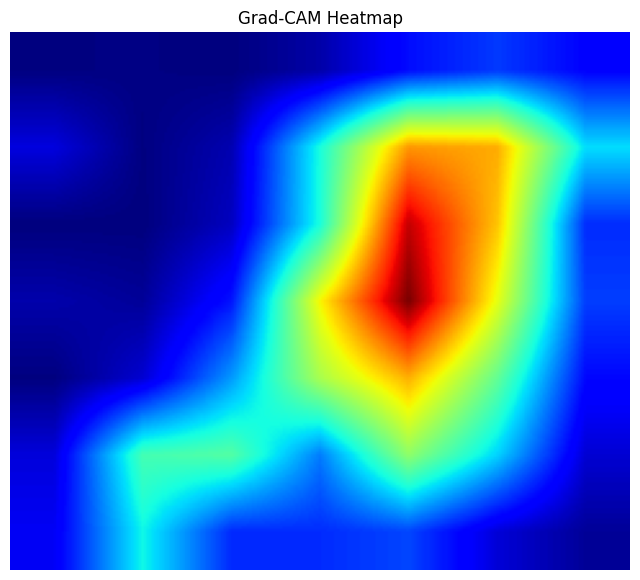

In [10]:
plt.figure(figsize=(8, 8))

plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.show()

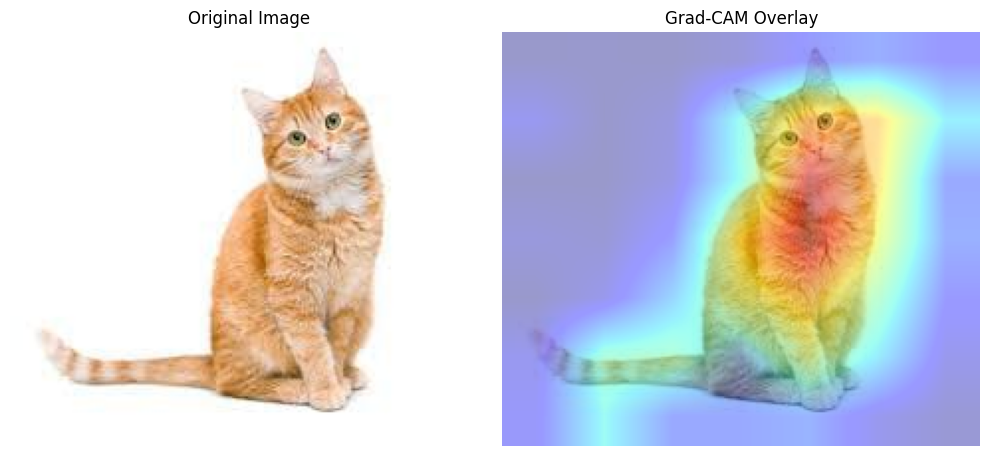

In [11]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()